In [2]:
import os
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=10"

# os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform" 
# This makes JAX allocate exactly what is needed on demand, and deallocate memory that is no longer needed (note that this is the only configuration that will deallocate GPU memory, instead of reusing it). This is very slow, so is not recommended for general use, but may be useful for running with the minimal possible GPU memory footprint or debugging OOM failures.

os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".95"
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import jax
import jax.numpy as jnp
from jax import random
import jax.numpy as jnp
from jax import random
import numpy as np
import matplotlib.pyplot as plt
from flax import linen as nn
import optax
import jax
import jax.numpy as jnp
from jax import random, jit
import optax
from tqdm import tqdm
import matplotlib.pyplot as plt
# Assuming equivalent JAX implementations
from src.subspace_curve import pytree_to_matrix
import wandb
from src.models import ResNet, ResNetBlock, init_t_lambda_to_phi, init_model_tube, init_model_phi
from jax_tqdm import scan_tqdm
from torch.utils.data import random_split
import torch
import torchvision
from torch.utils.data import TensorDataset
import pandas as pd
from src.models import MLPModel


%load_ext autoreload
%autoreload 2

# %env XLA_FLAGS="--xla_force_host_platform_device_count=10"
# os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=10"
# os.environ["XLA_FLAGS"] = ('--xla_force_host_platform_device_count=10 '
#                            '--xla_dump_to=xla_dump/')
%env XLA_FLAGS

#jax.devices("gpu")

'--xla_force_host_platform_device_count=10'

In [3]:
def gen_data(rng_seed, net_kwargs, **kwargs):
    rng_key = random.PRNGKey(rng_seed + 1133)
    x = jnp.linspace(-2, 2, 100)
    x = x[(jnp.abs(x) > 0.6)].reshape(-1, 1)

    # define ground trouth model
    rng_key, rng_init = random.split(rng_key)
    model_gen = MLPModel(**net_kwargs)
    params = model_gen.init(rng_init, x)

    # generate train data
    y_gt = model_gen.apply(params, x).squeeze()
    rng_key, rng = random.split(rng_key)
    y = y_gt + jax.random.normal(rng, y_gt.shape) * 0.05

    # generate valid data
    x_val = jnp.linspace(-2, 2, 25)
    x_val = x_val[(jnp.abs(x_val) > 0.6)].reshape(-1, 1)
    y_gt_val = model_gen.apply(params, x_val).squeeze()
    rng_key, rng = random.split(rng_key)
    y_val = y_gt_val + jax.random.normal(rng, y_gt_val.shape) * 0.05

    xt = jnp.linspace(-2.5, 2.5, 1000).reshape(-1, 1)
    rng_key, rng = random.split(rng_key)
    y_gtt = model_gen.apply(params, xt).squeeze()
    yt = y_gtt + jax.random.normal(rng, y_gtt.shape) * 0.05

    return x, y, x_val, y_val, xt, yt, y_gtt

Data shapes: (70, 1) (70,) (1000, 1) (1000,)


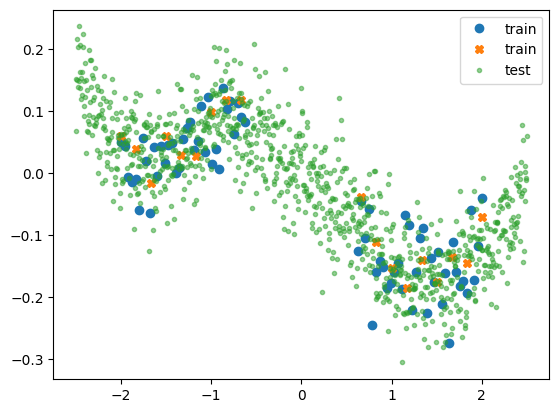

In [4]:
config = {'rng_seed': 0,
          'num_epochs': 500,
          'batch_size': 100,
          'optimizer_conf': {'name': "optax.sgd", 'kwargs': {'learning_rate': 0.05, 'momentum': 0.9, 'nesterov': True}},
          'net_kwargs': {'depth': 10, 'width': 10, 'activation': 'elu'}}

x, y, x_val, y_val, xt, yt, y_gtt = gen_data(**config)
plt.plot(x, y, 'o', label='train')
plt.plot(x_val, y_val, 'X', label='train')
plt.plot(xt, yt, '.', label='test', alpha=0.5)
plt.legend()
print("Data shapes:", x.shape, y.shape, xt.shape, yt.shape)


In [29]:
jax.random.randint(random.PRNGKey(0), (10,), 0, 3)

Array([2, 1, 2, 1, 2, 0, 0, 1, 1, 0], dtype=int32)

In [11]:
from src.subspace_curve import CategorySubspace
from src.models import ResNet, ResNetBlock, MLPModel

temp_x = jnp.ones((10, 32, 32, 3))
temp_y = jax.random.randint(random.PRNGKey(0), (10,), 0, 3)
model = ResNet(num_classes=3, num_blocks=(1,), block_class=ResNetBlock, act_fn=nn.elu)

s_model = CategorySubspace(
    model=model,
    k=1,
    weight_decay=0.01,
    perm_spec=None,  # PermutationSpec(2, 3),
    natural_parameterization=False,
    mutuable_param_name='batch_stats' if isinstance(model, ResNet) else False
)
mask = s_model.init_mask(temp_x, all_curves=False)
# mask['Dense_2']['bias'] = False  # do curve bias
# mask['Dense_2']['kernel'] = False  # do curve kernel
params = s_model.init_params(random.PRNGKey(0), temp_x, mask)
for p in jax.tree.flatten(params['params'])[0]:
    print(p.shape)
out, batch_stats = s_model(params['params'], params['batch_stats'], t=0.5, x=temp_x, train=True)
print("Out shape: ", out.shape)

opti = optax.sgd(learning_rate=0.05, momentum=0.9, nesterov=True)
opt_state = opti.init(params['params'])
loss, params, opt_state, grads = s_model.train_step(random.PRNGKey(0), params, temp_x, temp_y, opt_state=opt_state, optimizer=opti)
# Check that the output shapes are the same
loss

(16,)
(16,)
(3, 3, 3, 16)
(3,)
(16, 3)
(16,)
(16,)
(16,)
(16,)
(3, 3, 16, 16)
(3, 3, 16, 16)
Out shape:  (10, 3)


Array(2.390133, dtype=float32)

In [7]:
from src.subspace_curve import RegressionSubspace, DistRegressionSubspace
temp_x = jnp.ones((10, 1))
temp_y = jax.random.normal(random.PRNGKey(0), (10,1))
model = MLPModel(depth=3, width=5, activation='elu')


s_model = DistRegressionSubspace(
    model=model,
    k=1,
    weight_decay=0.01,
    perm_spec=None,  # PermutationSpec(2, 3),
    natural_parameterization=False,
    mutuable_param_name='batch_stats' if isinstance(model, ResNet) else False
)
mask = s_model.init_mask(temp_x, all_curves=False)
# mask['Dense_2']['bias'] = False  # do curve bias
# mask['Dense_2']['kernel'] = False  # do curve kernel
params = s_model.init_params(random.PRNGKey(0), temp_x, mask)
for p in jax.tree.flatten(params['params'])[0]:
    print(p.shape)
out, batch_stats = s_model(params['params'], {}, t=0.5, x=temp_x, train=True)
print("Out shape: ", out.shape)

opti = optax.sgd(learning_rate=0.05, momentum=0.9, nesterov=True)
opt_state = opti.init(params['params'])
loss, params, opt_state, grads = s_model.train_step(random.PRNGKey(0), params, temp_x, temp_y, opt_state=opt_state, optimizer=opti)
# Check that the output shapes are the same
loss

{'Dense_0': {'bias': False, 'kernel': False}, 'Dense_1': {'bias': False, 'kernel': False}, 'Dense_2': {'bias': False, 'kernel': False}, 'Dense_3': {'bias': False, 'kernel': False}}
(5,)
(3, 5)
(5,)
(5, 5)
(5,)
(5, 5)
(1,)
(5, 1)
()
Out shape:  (10, 1)


Array(1.1929004, dtype=float32)

In [34]:
a = 0.1
jnp.array(a)

Array(0.1, dtype=float32, weak_type=True)

In [11]:
params['']

KeyError: ''

In [50]:
params_cat['params']['ResNetBlock_0']['BatchNorm_0'][''] = {}

In [51]:
params_cat['params']['ResNetBlock_0']['BatchNorm_0']

{'bias': Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],      dtype=float32),
 'scale': Array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],      dtype=float32),
 '': {}}

In [ ]:
model.apply(params_cat, temp_x, train=True, mutable='batch_stats')

In [49]:
params['params']['ResNetBlock_0']['BatchNorm_0']

{'bias': Array([ 2.0043892e-04, -3.0216024e-05, -4.3754673e-04,  9.6455791e-05,
         9.6938338e-06, -3.0280877e-05,  1.7298599e-04,  1.2106768e-04,
        -3.5604015e-05,  1.2426439e-04,  5.2913390e-05, -4.3167354e-05,
        -1.7445991e-04,  4.5696608e-05,  5.1523617e-05,  6.9075766e-05],      dtype=float32),
 'scale': Array([0.9981578 , 0.9979357 , 0.9980732 , 0.99782413, 0.99796236,
        0.9979967 , 0.9980464 , 0.99854004, 0.9979446 , 0.99802935,
        0.9990367 , 0.9982837 , 0.99799216, 0.9976188 , 0.9981981 ,
        0.99790287], dtype=float32)}

In [32]:
loss

Array(3.569724, dtype=float32)

In [6]:
np.log(2.)

0.6931471805599453

In [139]:
out, stats = model.apply(params, temp_x, train=True, mutable='batch_stats')
stats

{'batch_stats': {'BatchNorm_0': {'mean': Array([-0.01229532,  0.00139667,  0.00169217, -0.00098316,  0.00230989,
           0.00079436, -0.00425513, -0.00287171,  0.00112672,  0.00700976,
           0.00179704,  0.00763102,  0.00361926, -0.00098085,  0.01529598,
           0.00156178], dtype=float32),
   'var': Array([0.9902998 , 0.9900645 , 0.9900353 , 0.9900119 , 0.990078  ,
          0.99006176, 0.9900388 , 0.9901291 , 0.9900555 , 0.9904711 ,
          0.99003094, 0.9901656 , 0.9900271 , 0.99001426, 0.9904508 ,
          0.990201  ], dtype=float32)},
  'ResNetBlock_0': {'BatchNorm_0': {'mean': Array([-0.00093103, -0.00097982,  0.00064342, -0.0034572 , -0.00101494,
           -0.00198296,  0.00069654, -0.0017558 , -0.0001359 , -0.0061989 ,
           -0.0011547 ,  0.00014258,  0.00156976,  0.00184694,  0.00163072,
           -0.0023805 ], dtype=float32),
    'var': Array([1.0049145 , 0.9968031 , 0.9960377 , 0.9938634 , 0.9949915 ,
           0.99341714, 1.0012898 , 0.9982632 , 0.9974

In [128]:
stats['batch_stats'].keys()

dict_keys(['BatchNorm_0', 'ResNetBlock_0'])

In [95]:
params.keys()

dict_keys(['params', 'batch_stats'])

In [90]:
model.init(random.PRNGKey(0), jnp.ones((10, 32,32,3))).keys()

dict_keys(['params', 'batch_stats'])

In [87]:
mask.keys()

dict_keys(['BatchNorm_0', 'Conv_0', 'Dense_0', 'ResNetBlock_0', 'ResNetBlock_1', 'ResNetBlock_2', 'ResNetBlock_3'])

In [60]:
mask['Dense_10']['bias'] = True
mask

{'Dense_0': {'bias': False, 'kernel': False},
 'Dense_1': {'bias': False, 'kernel': False},
 'Dense_10': {'bias': True, 'kernel': False},
 'Dense_2': {'bias': False, 'kernel': False},
 'Dense_3': {'bias': False, 'kernel': False},
 'Dense_4': {'bias': False, 'kernel': False},
 'Dense_5': {'bias': False, 'kernel': False},
 'Dense_6': {'bias': False, 'kernel': False},
 'Dense_7': {'bias': False, 'kernel': False},
 'Dense_8': {'bias': False, 'kernel': False},
 'Dense_9': {'bias': False, 'kernel': False}}

In [65]:
jax.tree_util.tree_flatten_with_path(params['params'])

([((DictKey(key='Dense_0'), DictKey(key='bias')),
   Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)),
  ((DictKey(key='Dense_0'), DictKey(key='kernel')),
   Array([[-0.13922767,  0.9595996 , -0.08803711, -0.9222269 , -0.12535745,
            0.15886275,  0.12549743, -0.88641435, -0.6691398 , -0.47700125],
          [ 0.9020473 , -0.5310391 ,  0.16902646, -0.80450004, -0.16861625,
            0.04551712,  0.07807952, -0.29752722,  0.28121704, -0.07672697],
          [ 0.39316636,  1.1723027 , -0.39354447, -0.9030481 , -1.1167086 ,
           -0.08289517, -0.1465585 , -0.3794272 ,  0.36623192,  0.35886976]],      dtype=float32)),
  ((DictKey(key='Dense_1'), DictKey(key='bias')),
   Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)),
  ((DictKey(key='Dense_1'), DictKey(key='kernel')),
   Array([[ 2.87318408e-01,  2.44105101e-01,  4.63291466e-01,
           -2.47244060e-01, -2.07405552e-01, -5.46380766e-02,
            9.39024016e-02, -1.60810590e-01,  2.230024

In [61]:
jax.tree.flatten(mask)

([False,
  False,
  False,
  False,
  True,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False],
 PyTreeDef({'Dense_0': {'bias': *, 'kernel': *}, 'Dense_1': {'bias': *, 'kernel': *}, 'Dense_10': {'bias': *, 'kernel': *}, 'Dense_2': {'bias': *, 'kernel': *}, 'Dense_3': {'bias': *, 'kernel': *}, 'Dense_4': {'bias': *, 'kernel': *}, 'Dense_5': {'bias': *, 'kernel': *}, 'Dense_6': {'bias': *, 'kernel': *}, 'Dense_7': {'bias': *, 'kernel': *}, 'Dense_8': {'bias': *, 'kernel': *}, 'Dense_9': {'bias': *, 'kernel': *}}))

In [50]:
jax.tree.flatten(model.init(random.PRNGKey(0), jnp.ones((10, 1)))) 

([Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
  Array([[ 5.09199570e-04,  3.65258425e-01, -1.51396692e-01,
           6.62521660e-01, -6.11496270e-01,  8.14506531e-01,
          -8.19546700e-01, -4.47275817e-01,  3.11387599e-01,
          -3.03434730e-01],
         [ 1.24704719e+00,  5.03498673e-01,  5.69743693e-01,
           1.46983400e-01,  2.09070206e-01,  7.75782347e-01,
          -2.29955137e-01, -4.65844721e-01,  3.39531928e-01,
          -1.45278603e-01],
         [ 1.10406911e+00, -1.10773690e-01, -2.52988070e-01,
           1.20162874e-01,  1.31150043e+00,  6.72688007e-01,
          -5.87861061e-01, -9.59976688e-02, -6.34339675e-02,
           7.76401341e-01]], dtype=float32),
  Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
  Array([[ 0.04921617, -0.13863279,  0.23772022,  0.02114131,  0.7102933 ,
           0.04432254, -0.49467394, -0.08077101, -0.36748528, -0.04936177],
         [-0.16842954,  0.23103836,  0.17501305,  0.5104401 , -0.14

In [20]:
params = model.init(random.PRNGKey(0), jnp.ones((10, 1)))

PyTreeDef({'params': {'Dense_0': {'bias': *, 'kernel': *}, 'Dense_1': {'bias': *, 'kernel': *}, 'Dense_10': {'bias': *, 'kernel': *}, 'Dense_2': {'bias': *, 'kernel': *}, 'Dense_3': {'bias': *, 'kernel': *}, 'Dense_4': {'bias': *, 'kernel': *}, 'Dense_5': {'bias': *, 'kernel': *}, 'Dense_6': {'bias': *, 'kernel': *}, 'Dense_7': {'bias': *, 'kernel': *}, 'Dense_8': {'bias': *, 'kernel': *}, 'Dense_9': {'bias': *, 'kernel': *}}})

In [44]:
tt = {'a': jnp.ones((4, 2, 3)), 'b': {'ba': jnp.ones((4, 1, 2)), 'bb': jnp.ones((2, 1))}}
mask = {'a': True, 'b': {'ba': True, 'bb': False}}
coeff = jnp.array([0.1, 0.2, 0.3, 0.2])
sample_param = jax.tree.map(
        lambda x, m: jnp.einsum('k,k...->...',coeff, x) if m else x,
        tt,
        mask
    )

jax.tree.flatten(sample_param)

([Array([[0.8, 0.8, 0.8],
         [0.8, 0.8, 0.8]], dtype=float32),
  Array([[0.8, 0.8]], dtype=float32),
  Array([[1.],
         [1.]], dtype=float32)],
 PyTreeDef({'a': *, 'b': {'ba': *, 'bb': *}}))

In [46]:
jax.tree.map(lambda x: False, tt)

{'a': False, 'b': {'ba': False, 'bb': False}}

In [29]:
jax.tree_util.tree_leaves_with_path(tt)

[((DictKey(key='a'), DictKey(key='ba')),
  Array([[1., 1., 1.],
         [1., 1., 1.]], dtype=float32)),
 ((DictKey(key='a'), DictKey(key='bb')),
  Array([[1., 1., 1.],
         [1., 1., 1.]], dtype=float32)),
 ((DictKey(key='b'), DictKey(key='ba')),
  Array([[1., 1., 1.],
         [1., 1., 1.]], dtype=float32)),
 ((DictKey(key='b'), DictKey(key='bb')),
  Array([[1., 1., 1.],
         [1., 1., 1.]], dtype=float32))]

In [ ]:
def single_model_train(logger, config):
    '''' example config:
    config = {
        'rng_seed': 0,
        'num_epochs': 500,
        'batch_size': 100,
        'optimizer_conf': {'name': "optax.sgd", 'kwargs': {'learning_rate': 0.05, 'momentum': 0.9, 'nesterov': True}},
        'net_kwargs':{'num_blocks': (3, 3, 3),
                      'c_hidden': (16, 32, 64),
                      'num_classes': 10,
                      'act_fn': relu,
                      'block_class': ResNetBlock}}
    '''
    config['net_kwargs']['activation'] = getattr(nn, config['net_kwargs']['activation'])
    rng_key = random.PRNGKey(config['rng_seed'])

    # Load data
    x, y, x_val, y_val, x_test, y_test, _ = gen_data(**config)
    
    net = MLPModel(**config['net_kwargs'])
    rng_key, init_key = random.split(rng_key)
    params = net.init(init_key, x[0:2])
    
    def _predict(params, state_params, inputs, train):
        # Predict logits from inputs and parameters
        all_params = {"trainable": params, "state": state_params}

        def train_fn(inputs):
            logits, net_state = net.apply(
                all_params, inputs, train=True, mutable=["state_params"]
            )
            return logits, net_state

        def eval_fn(inputs):
            logits = net.apply(all_params, inputs, train=False, mutable=False)
            net_state = {"batch_stats": bn_params}
            return logits, net_state

        logits, net_state = jax.lax.cond(
            train, lambda x: train_fn(x), lambda x: eval_fn(x), inputs
        )
        return logits, net_state['batch_stats']


    def loss_fn(params, state_params, inputs, targets, train:bool):
        def l2_loss(x, alpha):
            return alpha * (x ** 2).sum()
        
        logits, stats_params = _predict(params, bn_params, inputs, train)
        #   print(logits.shape, targets.shape)
        loss = jnp.mean(
            optax.losses.softmax_cross_entropy_with_integer_labels(
                logits=logits, labels=targets)
        )
        loss = jax.lax.cond(train, lambda x: x+sum(l2_loss(w, alpha=1e-4)
                    for w in jax.tree.leaves(params)), lambda x: x, loss)
        return loss, stats_params
    

    # Train
    optimizer_conf = config['optimizer_conf']
    if isinstance(optimizer_conf['kwargs']['learning_rate'], dict):
        lr_schedule = eval(optimizer_conf['kwargs']['learning_rate']['name'])(
            **optimizer_conf['kwargs']['learning_rate']['kwargs'])
    else:
        iter_per_epoch_train = len(x) // config['batch_size']
        lr_schedule = optax.linear_onecycle_schedule(
            config['num_epochs'] * iter_per_epoch_train, config['optimizer_conf']['kwargs']['learning_rate'])
    optimizer_conf['kwargs']['learning_rate'] = lr_schedule
    optimizer = eval(optimizer_conf['name'])(**optimizer_conf['kwargs'])
    opt_state = optimizer.init(params['params'])

    # Train
    best_loss = np.inf
    best_params = params
    def setup_metrics(batch_size, x, target):
        def acc_fn(params):
            x_ = x.reshape(-1, batch_size, 32, 32, 3)
            y_ = target.reshape(-1, batch_size)

            def pred(carry, x):
                logits, _ = _predict(
                    params['params'], params['batch_stats'], x, train=False)
                return None, logits
            _, logits = jax.lax.scan(pred, None, x_)
            loss = jnp.mean(
                optax.losses.softmax_cross_entropy_with_integer_labels(
                    logits=logits, labels=y_)
            )
            acc = jnp.mean(jnp.argmax(logits, axis=-1) == y_)
            return {'Acc':acc, 'Loss':loss}
        return acc_fn

    valid_metrics_fn = setup_metrics(250, x_val, y_val)

    def train_batch(carry, batch):
        x_, y_ = batch
        rng_key, params, opt_state, best_loss, best_params = carry
        rng_key, subkey = random.split(rng_key)

        net_params, stats_params = params['params'], params['batch_stats']

        (loss, stats_params), grads = jax.value_and_grad(loss_fn, argnums=0, has_aux=True)(net_params, stats_params, x_, y_, train=True)
        updates, opt_state = optimizer.update(grads, opt_state, net_params)
        net_params = optax.apply_updates(net_params, updates)

        return (rng_key, {'params': net_params, 'batch_stats': stats_params}, opt_state, best_loss, best_params), loss

    @scan_tqdm(config['num_epochs'])
    def train(carry, _):
        rng_key = carry[0]
        rng_key, subkey = random.split(rng_key)
        shuffel = jax.random.permutation(subkey, jnp.arange(y.shape[0]))
        # data augmentation
        rng_key, x_ = jax.lax.scan(augment, rng_key, x)
        # x_ = x
        x_ = x_[shuffel].reshape(-1, config['batch_size'], 32, 32, 3)
        y_ = y[shuffel].reshape(-1, config['batch_size'])
        carry, loss_batch = jax.lax.scan(
            train_batch, carry, (x_, y_))
        
        # validate
        loss_epoch = jnp.mean(loss_batch)
        params, best_loss, best_params = carry[1], carry[3], carry[4]

        metrics = valid_metrics_fn(params)
        val_loss = metrics['Loss']
        best_params = jax.lax.cond(
            val_loss < best_loss, lambda x: params, lambda x: best_params, None)
        best_loss = jnp.minimum(best_loss, val_loss)

        return (rng_key, params, carry[2], best_loss, best_params), (loss_batch, val_loss, metrics['Acc'])


    carry = (rng_key, params, opt_state, best_loss, best_params)
    # start training
    carry, (losses, valid_losses, valid_acc) = jax.lax.scan(train, carry, jnp.arange(config['num_epochs']))
    rng_key, params, opt_state, best_loss, best_params = carry

    # log losses for wandb
    n_steps_e = losses.shape[1]
    epochs = np.repeat(np.arange(config['num_epochs']), n_steps_e)
    _ = [logger.log({"train_loss": l, "valid_loss": vl, 'valid ACC': vacc, 'epoch': e})
         for e, l, vl, vacc in zip(epochs, losses.flatten(), np.repeat(valid_losses, n_steps_e), np.repeat(valid_acc, n_steps_e))]

    fig, ax = plt.subplots(1, 1)
    ax.plot(np.array(losses).flatten(), alpha=0.2, label="train")
    ax.plot(np.arange(n_steps_e, n_steps_e*config['num_epochs']+1, n_steps_e), np.array(
        valid_losses).flatten(), alpha=0.2, label="valid")
    ax.set_ylabel("nll")
    ax.set_xlabel("steps")
    ax.legend()
    logger.log(
            {'Nll vs epoch': wandb.Image(fig)})
    
    # log test performance
    test_metrics_fn = setup_metrics(250, x_test, y_test)
    test_metrics = test_metrics_fn(params)
    logger.log({'test_loss': test_metrics['Loss'], 'test_acc': test_metrics['Acc']})
    test_metrics = test_metrics_fn(best_params)
    logger.log({'test_loss_best': test_metrics['Loss'], 'test_acc_best': test_metrics['Acc']})
    
    print("Save artifacts")
    jnp.save(f'tmp_files/{logger.id}_params.npy', best_params)
    jnp.save(f'tmp_files/{logger.id}_last_params.npy', params)
    print("add files to artifact")
    # create artifact for storing parameters
    artifact = wandb.Artifact(name="params", type="pytree")
    artifact.add_file(f'tmp_files/{logger.id}_params.npy')
    artifact.add_file(f'tmp_files/{logger.id}_last_params.npy')
    print("Log artifact")
    logger.log_artifact(artifact)

    logger.finish()